# Exoplanet Detection using Machine Learning
Detect stars that host exoplanets from Kepler light curves (brightness over time).
A planet passing in front of its star causes small **dips** in brightness that **repeat regularly**.

**Pipeline:** merge data → clean each star's curve → FFT band features → Random Forest (class-weighted) → tuned threshold → evaluation.

In [ ]:
!pip install --quiet numpy pandas matplotlib seaborn scipy scikit-learn imbalanced-learn joblib

In [13]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4" 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy.ndimage import median_filter, gaussian_filter1d
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

%matplotlib inline
sns.set(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and merge data
`exoTrain.csv` (37 planets) + `exoTest.csv` (5 planets) are merged into one dataset with **42 planets**.
Labels: 2 → planet (1), 1 → non-planet (0).

In [14]:
train = pd.read_csv("exoTrain.csv")
test  = pd.read_csv("exoTest.csv")
df = pd.concat([train, test], ignore_index=True)

y = (df["LABEL"] == 2).astype(int).values
X = df.drop(columns="LABEL").values.astype(float)

print("Shape:", X.shape)
print("Planets:", y.sum(), "| Non-planets:", (y == 0).sum(), "| Planet fraction:", round(y.mean(), 4))
print("Missing values:", np.isnan(X).sum())

Shape: (5657, 3197)
Planets: 42 | Non-planets: 5615 | Planet fraction: 0.0074
Missing values: 0


## 2. Clean each star's light curve
For every star separately:
1. **Remove slow drift** (subtract a median filter) so small dips are visible.
2. **Scale per star** so bright and faint stars are comparable.
3. **Clip upward spikes** (planets only cause downward dips).
4. **Light smoothing** to reduce noise.

In [15]:
def clean_star(f):
    f = f - median_filter(f, size=101, mode="nearest")  # remove slow drift
    f = f / (f.std() + 1e-9)                             # per-star scaling
    f = np.clip(f, None, 4)                              # cut upward spikes
    return gaussian_filter1d(f, sigma=2)                 # light smoothing

X_clean = np.array([clean_star(r) for r in X])
print("Cleaned shape:", X_clean.shape)

Cleaned shape: (5657, 3197)


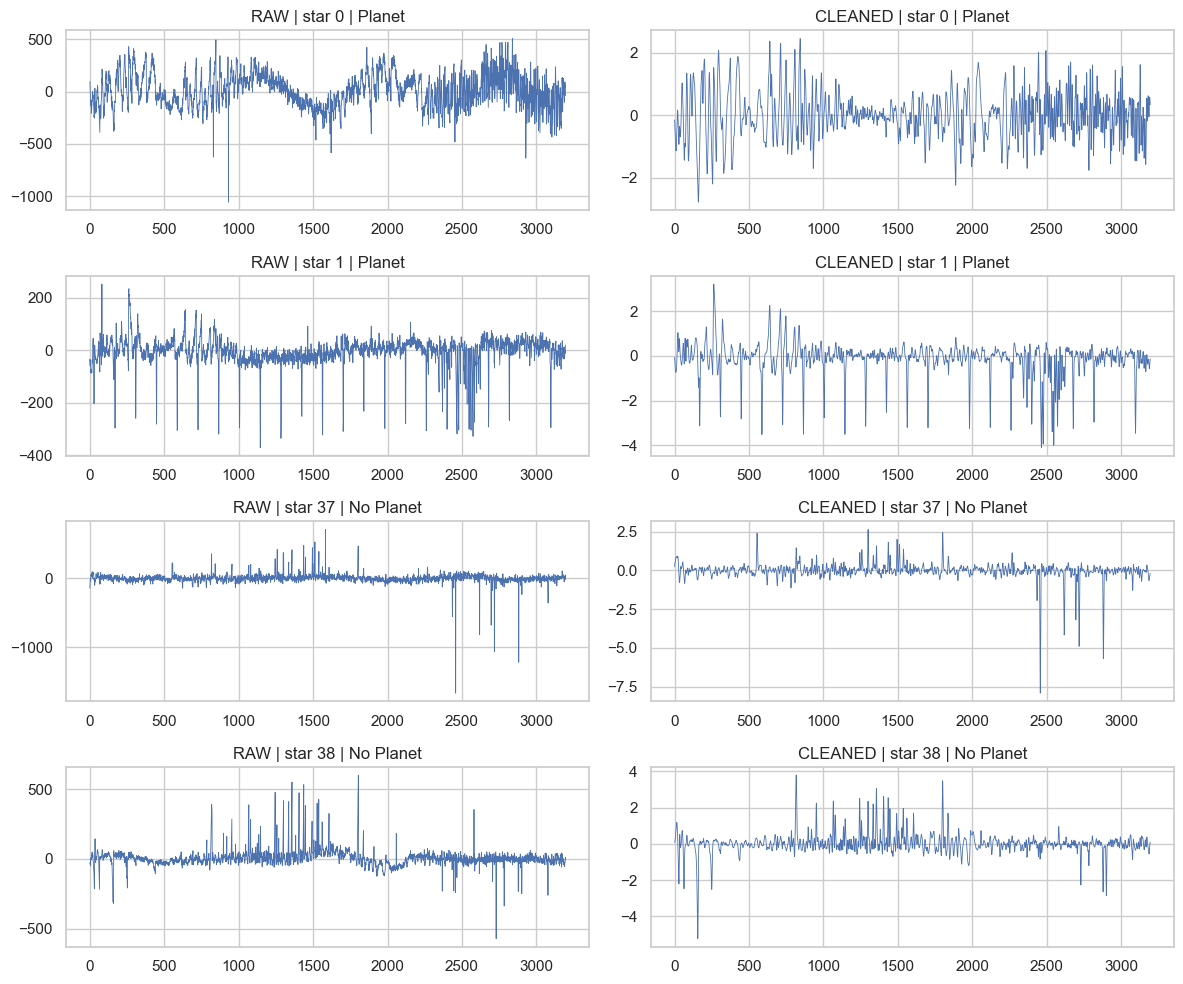

In [16]:
idx = list(np.where(y == 1)[0][:2]) + list(np.where(y == 0)[0][:2])
fig, ax = plt.subplots(4, 2, figsize=(12, 10))
for r, i in enumerate(idx):
    name = "Planet" if y[i] == 1 else "No Planet"
    ax[r, 0].plot(X[i], lw=0.6);       ax[r, 0].set_title(f"RAW | star {i} | {name}")
    ax[r, 1].plot(X_clean[i], lw=0.6); ax[r, 1].set_title(f"CLEANED | star {i} | {name}")
plt.tight_layout(); plt.show()

## 3. Feature extraction: FFT bands
A dip can occur at any time in a curve, so comparing curves point by point does not work.
The **FFT** measures *how strongly the curve repeats at each speed*, regardless of *when* the dips happen.
The spectrum (~1,598 values) is grouped into **100 bands**, keeping the strongest value in each band → 100 features per star.

In [17]:
def fft_bands(X_clean, n_bands=100):
    spec = np.log1p(np.abs(np.fft.rfft(X_clean, axis=1))[:, 1:])
    edges = np.linspace(0, spec.shape[1], n_bands + 1, dtype=int)
    return np.stack([spec[:, a:b].max(axis=1) for a, b in zip(edges[:-1], edges[1:])], axis=1)

F = fft_bands(X_clean)
print("Feature matrix:", F.shape)

Feature matrix: (5657, 100)


## 4. Evaluation function
All models are evaluated with **5-fold stratified cross-validation**, so every one of the 42 planets is tested once.
Accuracy alone is misleading (predicting "no planet" for every star gives ~99.3%), so we focus on **precision, recall and F1 for the planet class**.

In [19]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate_model(y_true, proba, model_name="Model", threshold=0.5):
    y_pred = (proba >= threshold).astype(int)
    print("=" * 55)
    print(f"Evaluation for: {model_name}  (threshold = {threshold})")
    print("=" * 55)
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_true, proba):.4f}\n")
    print("Classification Report:")
    print(classification_report(y_true, y_pred, digits=4,
                                target_names=["No Planet (0)", "Planet (1)"], zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No Planet (0)", "Planet (1)"],
                yticklabels=["No Planet (0)", "Planet (1)"])
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion Matrix: {model_name}")
    plt.show()
    return dict(Model=model_name,
                Accuracy=accuracy_score(y_true, y_pred),
                Precision=precision_score(y_true, y_pred, zero_division=0),
                Recall=recall_score(y_true, y_pred),
                F1=f1_score(y_true, y_pred),
                ROC_AUC=roc_auc_score(y_true, proba))

## 5. Baseline (old approach, for comparison)
Raw flux → StandardScaler → SMOTE → KNN / Logistic Regression.
*This cell is slow (a few minutes).*

Evaluation for: Baseline: LogReg + SMOTE (raw)  (threshold = 0.5)
Accuracy : 0.9477
ROC-AUC  : 0.6066

Classification Report:
               precision    recall  f1-score   support

No Planet (0)     0.9944    0.9526    0.9731      5615
   Planet (1)     0.0432    0.2857    0.0750        42

     accuracy                         0.9477      5657
    macro avg     0.5188    0.6192    0.5240      5657
 weighted avg     0.9874    0.9477    0.9664      5657



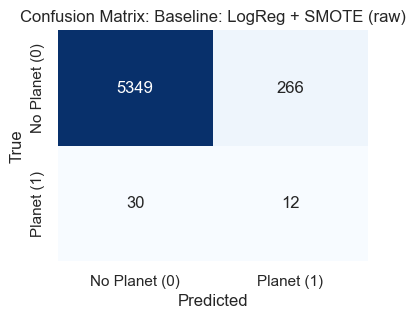

Evaluation for: Baseline: KNN + SMOTE (raw)  (threshold = 0.5)
Accuracy : 0.9691
ROC-AUC  : 0.6821

Classification Report:
               precision    recall  f1-score   support

No Planet (0)     0.9947    0.9740    0.9843      5615
   Planet (1)     0.0818    0.3095    0.1294        42

     accuracy                         0.9691      5657
    macro avg     0.5382    0.6418    0.5568      5657
 weighted avg     0.9879    0.9691    0.9779      5657



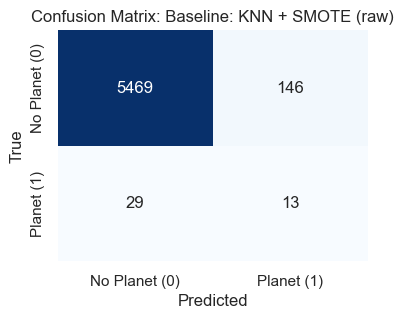

In [20]:
results, probas = [], {}

def old_pipeline(model):
    return ImbPipeline([("scale", StandardScaler()),
                        ("smote", SMOTE(random_state=RANDOM_STATE)),
                        ("model", model)])

for name, m in [("Baseline: LogReg + SMOTE (raw)", LogisticRegression(max_iter=2000)),
                ("Baseline: KNN + SMOTE (raw)", KNeighborsClassifier(n_neighbors=5))]:
    p = cross_val_predict(old_pipeline(m), X, y, cv=skf, method="predict_proba")[:, 1]
    probas[name] = p
    results.append(evaluate_model(y, p, name))

## 6. Final model: Random Forest on FFT bands
- **Class weights** replace SMOTE: missing a planet is penalised more, without creating synthetic light curves.
- **Threshold 0.13** instead of 0.5, so the model flags planets more readily.

Evaluation for: Final: Random Forest (cleaned + FFT)  (threshold = 0.13)
Accuracy : 0.9972
ROC-AUC  : 0.9419

Classification Report:
               precision    recall  f1-score   support

No Planet (0)     0.9977    0.9995    0.9986      5615
   Planet (1)     0.9062    0.6905    0.7838        42

     accuracy                         0.9972      5657
    macro avg     0.9520    0.8450    0.8912      5657
 weighted avg     0.9970    0.9972    0.9970      5657



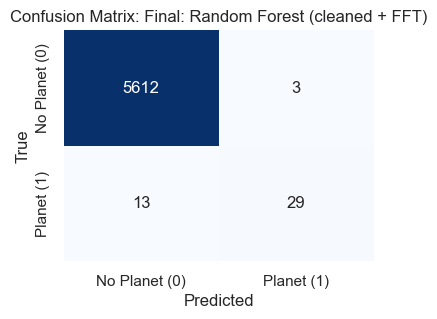

In [21]:
final_model = RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                     class_weight="balanced_subsample",
                                     random_state=RANDOM_STATE, n_jobs=-1)
THRESHOLD = 0.13

name = "Final: Random Forest (cleaned + FFT)"
p = cross_val_predict(final_model, F, y, cv=skf, method="predict_proba")[:, 1]
probas[name] = p
results.append(evaluate_model(y, p, name, threshold=THRESHOLD))

## 6b. Logistic Regression and KNN on FFT features
Same FFT features, different models — shows how much of the gain comes from the **features** vs the **model**.
- Logistic Regression uses class weights.
- KNN has no class-weight option, so it uses SMOTE (on the 100 FFT features, which is reasonable, unlike on raw curves).

Evaluation for: LogReg (cleaned + FFT)  (threshold = 0.5)
Accuracy : 0.9855
ROC-AUC  : 0.9679

Classification Report:
               precision    recall  f1-score   support

No Planet (0)     0.9982    0.9872    0.9927      5615
   Planet (1)     0.3077    0.7619    0.4384        42

     accuracy                         0.9855      5657
    macro avg     0.6529    0.8745    0.7155      5657
 weighted avg     0.9931    0.9855    0.9885      5657



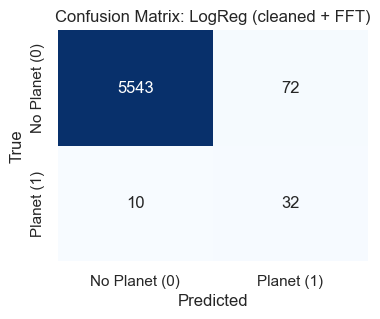

Evaluation for: KNN + SMOTE (cleaned + FFT)  (threshold = 0.5)
Accuracy : 0.9604
ROC-AUC  : 0.8783

Classification Report:
               precision    recall  f1-score   support

No Planet (0)     0.9982    0.9619    0.9797      5615
   Planet (1)     0.1301    0.7619    0.2222        42

     accuracy                         0.9604      5657
    macro avg     0.5641    0.8619    0.6010      5657
 weighted avg     0.9917    0.9604    0.9741      5657



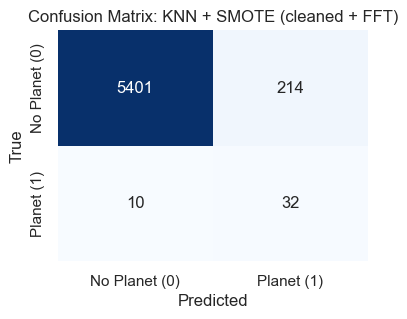

In [22]:
fft_models = {
    "LogReg (cleaned + FFT)": ImbPipeline([("scale", StandardScaler()),
                                            ("model", LogisticRegression(max_iter=5000, class_weight="balanced"))]),
    "KNN + SMOTE (cleaned + FFT)": ImbPipeline([("scale", StandardScaler()),
                                                 ("smote", SMOTE(random_state=RANDOM_STATE)),
                                                 ("model", KNeighborsClassifier(n_neighbors=5))]),
}
for name, m in fft_models.items():
    p = cross_val_predict(m, F, y, cv=skf, method="predict_proba")[:, 1]
    probas[name] = p
    results.append(evaluate_model(y, p, name))

## 7. ROC curves and results comparison

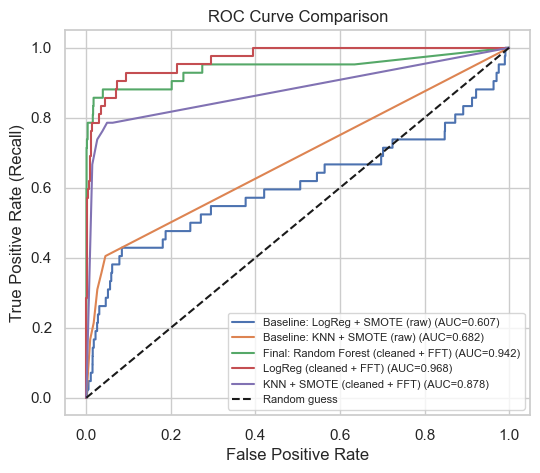

In [23]:
plt.figure(figsize=(6, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison"); plt.legend(fontsize=8); plt.show()

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Baseline: LogReg + SMOTE (raw),0.9477,0.0432,0.2857,0.0750,0.6066
Baseline: KNN + SMOTE (raw),0.9691,0.0818,0.3095,0.1294,0.6821
Final: Random Forest (cleaned + FFT),0.9972,0.9062,0.6905,0.7838,0.9419
LogReg (cleaned + FFT),0.9855,0.3077,0.7619,0.4384,0.9679
KNN + SMOTE (cleaned + FFT),0.9604,0.1301,0.7619,0.2222,0.8783


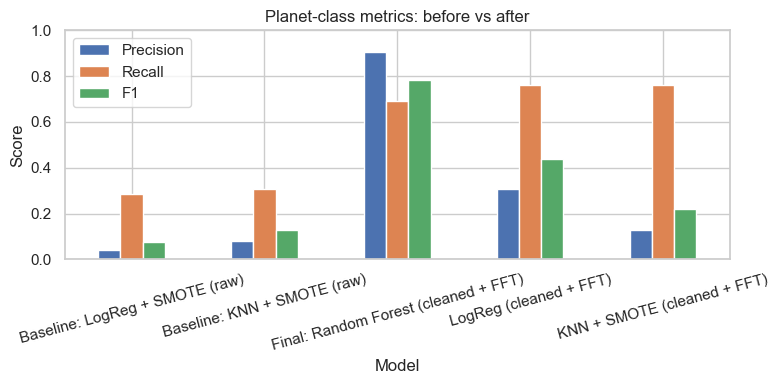

In [24]:
summary = pd.DataFrame(results).set_index("Model").round(4)
display(summary)

summary[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(8, 4), rot=15)
plt.title("Planet-class metrics: before vs after"); plt.ylim(0, 1); plt.ylabel("Score")
plt.tight_layout(); plt.show()

## 8. Train final model on all data and save

In [26]:
final_model.fit(F, y)
joblib.dump({"model": final_model, "threshold": THRESHOLD}, "exoplanet_rf_fft.joblib")
print("Model saved as exoplanet_rf_fft.joblib")

def predict_star(flux):
    """flux: 1D array of 3197 brightness values -> (probability, is_planet)"""
    feats = fft_bands(clean_star(np.asarray(flux, dtype=float))[None, :])
    prob = final_model.predict_proba(feats)[0, 1]
    return prob, bool(prob >= THRESHOLD)

prob, is_planet = predict_star(X[0])
print(f"Star 0 -> probability {prob:.3f}, planet = {is_planet} (true label = {y[0]})")

Model saved as exoplanet_rf_fft.joblib
Star 0 -> probability 0.703, planet = True (true label = 1)
